# Crowdcast: counting people with CSRNet, v2 (ShanghaiTech Part A)

**v1 result** ([01_counting_model_partA.ipynb](01_counting_model_partA.ipynb)): test MAE 94.3, RMSE 130.7.
Training stopped early after 5 epochs, with the best at epoch 2. Epoch 3 spiked
(val MAE 148 → 355), fine-tuning took ~30 min per epoch on CPU, and sparse photos were overcounted.

**What v2 changes, and why:**

| Change | v1 | v2 | Why |
|---|---|---|---|
| Learning rate while VGG-16 is frozen | 1e-4 | 3e-5 | The epoch-3 spike means steps were too big |
| What gets fine-tuned | all of VGG-16 | only VGG-16's last block (`block4`) | Early blocks hold generic edges/textures worth keeping; ~half the fine-tuning cost |
| Validation images | 30 (10%) | 45 (15%) | One dense photo swung the val score too much |
| Max epochs / early-stop patience | 10 / 3 | 20 / 5 | More time to learn, still stops before overfitting |

Everything else (data, density maps, model, augmentation, test set) is identical, so the
v1 → v2 comparison at the end isolates these changes. The 182 test images are only used at the end.

**Goal:** given a crowd photo, predict how many people are in it.

**Approach:** CSRNet density estimation with transfer learning (Decisions #5 and #6):
- **Front end:** VGG-16 pretrained on ImageNet, up to `block4_conv3`.
- **Back end:** 6 dilated convolutions plus a 1×1 output conv, trained here.
- The model outputs a *density map*. Its sum is the predicted count.

**How we stop overfitting:**
1. **Validation set:** 15% of training images are held out and never trained on.
2. **Save the best epoch only:** keep the weights with the lowest validation MAE, not the last ones.
3. **Early stopping:** stop if validation MAE doesn't improve for 5 epochs.
4. **Augmentation:** random 256×256 crops plus left-right flips, so every epoch sees different patches.
5. **Careful transfer learning:** VGG-16 stays frozen for 3 epochs, then only its last block (`block4`) is fine-tuned at a smaller learning rate.
6. **Lower the learning rate when stuck** (halve it after 2 epochs with no improvement), plus a small L2 weight penalty on the new layers.
7. **Proof:** count error on training images vs validation images is plotted after every epoch. If the two lines split apart, the model is memorising.

## 1. Setup

In [1]:
import os, time, json, warnings
warnings.filterwarnings("ignore", category=UserWarning, module="keras")   # harmless shuffle / optimizer-state notices
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow info logs
# oneDNN (TensorFlow's CPU speed-up library) made full-image counting ~60x slower on this
# machine (60s vs 1s per 704x1024 photo, measured 2026-11-08), so it's switched off.
# Must be set before TensorFlow is imported (restart the kernel if TF was already loaded).
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import numpy as np
import scipy.io as sio
from scipy.spatial import cKDTree
from PIL import Image
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model, regularizers
from IPython.display import display

print("TensorFlow", tf.__version__, "| NumPy", np.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU") or "none (training on CPU)")

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
PART_A = os.path.join(ROOT, "data", "shanghaitech", "ShanghaiTech", "part_A")
CACHE_DIR = os.path.join(ROOT, "data", "cache")
WEIGHTS_DIR = os.path.join(ROOT, "weights")
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(WEIGHTS_DIR, exist_ok=True)
BEST_WEIGHTS = os.path.join(WEIGHTS_DIR, "csrnet_partA_v2_best.weights.h5")
V1_WEIGHTS = os.path.join(WEIGHTS_DIR, "csrnet_partA_best.weights.h5")   # for the v1 vs v2 comparison

TensorFlow 2.20.0 | NumPy 2.5.4
GPUs: none (training on CPU)


In [2]:
# ---- Settings ----
SEED = 42
VAL_FRACTION = 0.15      # share of training images held out for validation
CROP = 256               # training patch size (multiple of 8)
CROPS_PER_IMAGE = 4      # random patches per image per epoch
BATCH_SIZE = 8
EPOCHS = 20
FREEZE_EPOCHS = 3        # epochs with VGG-16 frozen before fine-tuning it
LR_HEAD = 3e-5           # learning rate while VGG-16 is frozen
LR_FINETUNE = 1e-5       # learning rate once VGG-16 is unfrozen
L2 = 1e-4                # weight penalty on the new (back-end) layers
EARLY_STOP_PATIENCE = 5  # epochs without val improvement before stopping
LR_PATIENCE = 2          # epochs without val improvement before halving the LR
DENSITY_SCALE = 100.0    # targets are multiplied by this so values aren't tiny
DOWNSAMPLE = 8           # CSRNet output is 1/8 of the input size
FINETUNE_BLOCKS = ("block4",)   # VGG-16 blocks unfrozen after FREEZE_EPOCHS

tf.keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

## 2. Load Part A

Each image has a `.mat` file with the (x, y) position of every head.
The official split is 300 train and 182 test images. We take 10% of train as validation.

In [3]:
def load_split(split):
    img_dir = os.path.join(PART_A, f"{split}_data", "images")
    gt_dir = os.path.join(PART_A, f"{split}_data", "ground-truth")
    names = sorted(os.listdir(img_dir), key=lambda n: int(n.split("_")[1].split(".")[0]))
    items = []
    for name in names:
        info = sio.loadmat(os.path.join(gt_dir, "GT_" + name.replace(".jpg", ".mat")))["image_info"][0, 0][0, 0]
        img = Image.open(os.path.join(img_dir, name))
        items.append({"name": name, "points": info[0].astype(np.float32),
                      "count": float(info[1][0, 0]), "gray": img.mode == "L",
                      "image": np.array(img.convert("RGB"))})
    return items

t0 = time.time()
train_all = load_split("train")
test = load_split("test")

perm = rng.permutation(len(train_all))
n_val = int(round(VAL_FRACTION * len(train_all)))
val = [train_all[i] for i in perm[:n_val]]
train = [train_all[i] for i in perm[n_val:]]
print(f"Loaded in {time.time()-t0:.1f}s -> train {len(train)}, val {len(val)}, test {len(test)}")

for nm, items in [("train", train), ("val", val), ("test", test)]:
    c = np.array([it["count"] for it in items])
    print(f"{nm:>5}: people per image min {c.min():.0f}, mean {c.mean():.0f}, max {c.max():.0f}"
          f" | grayscale images: {sum(it['gray'] for it in items)}")

Loaded in 11.3s -> train 255, val 45, test 182
train: people per image min 33, mean 538, max 3138 | grayscale images: 8
  val: people per image min 49, mean 561, max 2197 | grayscale images: 3
 test: people per image min 66, mean 433, max 2256 | grayscale images: 9


## 3. Density maps (geometry-adaptive kernel)

Each head becomes a small Gaussian blob that sums to 1, so **sum of the map = number of people**.
In dense areas heads are small, so the blob is narrow: its width is 0.3 × the average distance to
the 3 nearest heads (the kernel from the MCNN/CSRNet papers).

CSRNet outputs a map 8× smaller than the image, so each map is **sum-pooled** 8×8. That keeps the
total the same. Maps are cached in `data/cache/` so this runs once.

In [4]:
MEAN_RGB = np.array([124, 117, 104], dtype=np.uint8)   # ImageNet mean: padding with it becomes ~0 after preprocessing

def padded_size(h, w):
    # Round up to a multiple of 8, and at least one crop in size.
    up = lambda v: max(CROP, int(np.ceil(v / DOWNSAMPLE)) * DOWNSAMPLE)
    return up(h), up(w)

def gaussian_1d(center, sigma, size):
    # Gaussian over pixel indices that fall inside the image.
    r = int(np.ceil(3 * sigma))
    lo, hi = max(0, int(center) - r), min(size, int(center) + r + 1)
    idx = np.arange(lo, hi)
    return lo, hi, np.exp(-0.5 * ((idx - center) / sigma) ** 2)

def density_map(points, h, w, beta=0.3, k=3, sigma_single=15.0):
    dmap = np.zeros((h, w), dtype=np.float32)
    inside = (points[:, 0] >= 0) & (points[:, 0] < w) & (points[:, 1] >= 0) & (points[:, 1] < h)
    pts = points[inside]
    if len(pts) == 0:
        return dmap, 0
    if len(pts) == 1:
        sigmas = np.array([sigma_single])
    else:
        d, _ = cKDTree(pts).query(pts, k=min(k + 1, len(pts)))
        sigmas = np.clip(beta * d[:, 1:].mean(axis=1), 1.0, 50.0)
    for (x, y), s in zip(pts, sigmas):
        y0, y1, gy = gaussian_1d(y, s, h)
        x0, x1, gx = gaussian_1d(x, s, w)
        blob = np.outer(gy, gx)
        dmap[y0:y1, x0:x1] += blob / blob.sum()   # each person adds exactly 1
    return dmap, len(pts)

def sum_pool(dmap, hp, wp):
    padded = np.zeros((hp, wp), dtype=np.float32)
    padded[:dmap.shape[0], :dmap.shape[1]] = dmap
    return padded.reshape(hp // DOWNSAMPLE, DOWNSAMPLE, wp // DOWNSAMPLE, DOWNSAMPLE).sum(axis=(1, 3))

def pad_image(img, hp, wp):
    out = np.empty((hp, wp, 3), dtype=np.uint8)
    out[:] = MEAN_RGB
    out[:img.shape[0], :img.shape[1]] = img
    return out

cache_file = os.path.join(CACHE_DIR, "partA_density_adaptive_v1.npz")
everything = {f"train/{it['name']}": it for it in train_all} | {f"test/{it['name']}": it for it in test}

t0 = time.time()
if os.path.exists(cache_file):
    cached = np.load(cache_file)
    for key, it in everything.items():
        it["full_density"] = None
        it["density"] = cached[key]
    print(f"Loaded cached density maps in {time.time()-t0:.1f}s")
else:
    to_save, dropped = {}, 0
    for key, it in everything.items():
        h, w = it["image"].shape[:2]
        dmap, n_inside = density_map(it["points"], h, w)
        dropped += len(it["points"]) - n_inside
        it["full_density"] = dmap
        it["density"] = to_save[key] = sum_pool(dmap, *padded_size(h, w))
    np.savez_compressed(cache_file, **to_save)
    print(f"Built {len(to_save)} density maps in {time.time()-t0:.1f}s "
          f"({dropped} head points fell outside their image and were dropped)")

for it in everything.values():
    it["padded"] = pad_image(it["image"], *padded_size(*it["image"].shape[:2]))

# Check: map totals should match the labelled counts (tiny gaps = the dropped out-of-bounds points).
gaps = np.array([abs(it["density"].sum() - it["count"]) for it in everything.values()])
print(f"|map sum - labelled count|: mean {gaps.mean():.3f}, max {gaps.max():.3f} people")

Loaded cached density maps in 0.2s


|map sum - labelled count|: mean 0.000, max 0.000 people


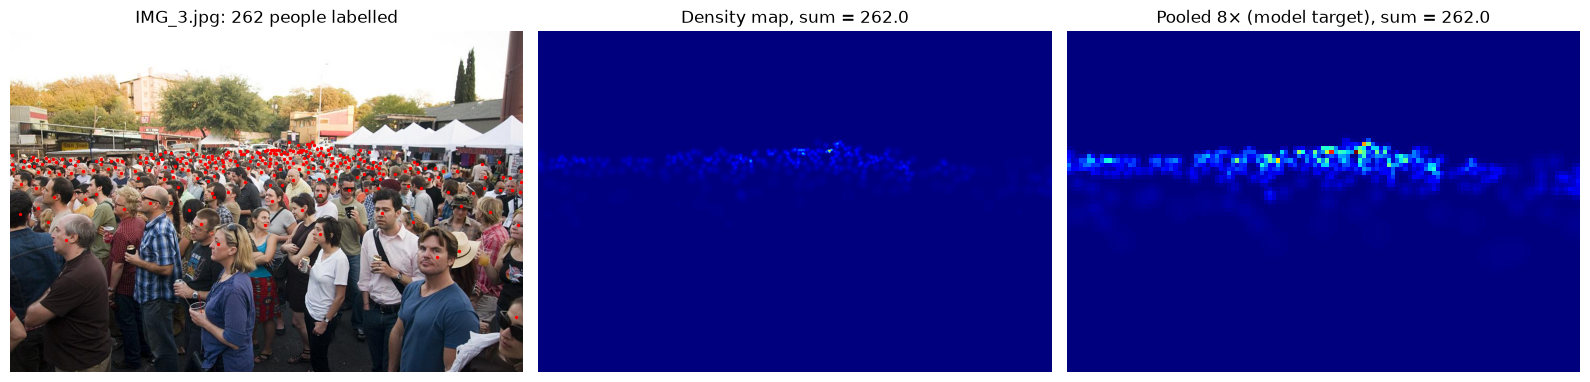

In [5]:
ex = train[0]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].imshow(ex["image"]); ax[0].set_title(f"{ex['name']}: {ex['count']:.0f} people labelled")
ax[0].scatter(ex["points"][:, 0], ex["points"][:, 1], s=2, c="red")
full = ex["full_density"] if ex["full_density"] is not None else density_map(ex["points"], *ex["image"].shape[:2])[0]
ax[1].imshow(full, cmap="jet"); ax[1].set_title(f"Density map, sum = {full.sum():.1f}")
ax[2].imshow(ex["density"], cmap="jet"); ax[2].set_title(f"Pooled 8× (model target), sum = {ex['density'].sum():.1f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 4. Baseline: always guess the average

Any model has to beat this. It predicts the mean training count for every image.

In [6]:
def mae_rmse(pred, true):
    err = np.asarray(pred) - np.asarray(true)
    return float(np.abs(err).mean()), float(np.sqrt((err ** 2).mean()))

mean_count = np.mean([it["count"] for it in train])
base_val = mae_rmse([mean_count] * len(val), [it["count"] for it in val])
base_test = mae_rmse([mean_count] * len(test), [it["count"] for it in test])
print(f"Mean-count baseline (always guess {mean_count:.0f}):")
print(f"  val  MAE {base_val[0]:.1f}, RMSE {base_val[1]:.1f}")
print(f"  test MAE {base_test[0]:.1f}, RMSE {base_test[1]:.1f}")

Mean-count baseline (always guess 538):
  val  MAE 320.0, RMSE 466.3
  test MAE 301.8, RMSE 368.6


## 5. Training data pipeline

Every epoch draws fresh random 256×256 crops (offsets on the 8-pixel grid so they line up with the
pooled target), flipped left-right half the time. Images go through VGG-16's own preprocessing.

In [7]:
preprocess = tf.keras.applications.vgg16.preprocess_input
OUT = CROP // DOWNSAMPLE

def random_crops():
    for i in rng.permutation(len(train) * CROPS_PER_IMAGE):
        it = train[i % len(train)]
        hp, wp = it["padded"].shape[:2]
        y = DOWNSAMPLE * rng.integers(0, (hp - CROP) // DOWNSAMPLE + 1)
        x = DOWNSAMPLE * rng.integers(0, (wp - CROP) // DOWNSAMPLE + 1)
        img = it["padded"][y:y + CROP, x:x + CROP]
        den = it["density"][y // DOWNSAMPLE:y // DOWNSAMPLE + OUT, x // DOWNSAMPLE:x // DOWNSAMPLE + OUT]
        if rng.random() < 0.5:
            img, den = img[:, ::-1], den[:, ::-1]
        yield preprocess(img.astype(np.float32)), (den * DENSITY_SCALE)[..., None].astype(np.float32)

train_ds = (tf.data.Dataset.from_generator(random_crops, output_signature=(
                tf.TensorSpec((CROP, CROP, 3), tf.float32), tf.TensorSpec((OUT, OUT, 1), tf.float32)))
            .batch(BATCH_SIZE).prefetch(2))
STEPS_PER_EPOCH = int(np.ceil(len(train) * CROPS_PER_IMAGE / BATCH_SIZE))

xb, yb = next(iter(train_ds))
print("batch images:", xb.shape, "| batch targets:", yb.shape, "| steps per epoch:", STEPS_PER_EPOCH)
print("people in this batch's crops:", np.round(yb.numpy().sum(axis=(1, 2, 3)) / DENSITY_SCALE, 1))

batch images: (8, 256, 256, 3) | batch targets: (8, 32, 32, 1) | steps per epoch: 128
people in this batch's crops: [ 11.7  45.5  38.2  29.6 414.6  69.3  97.1  12.7]


## 6. Build CSRNet

- **Front end:** VGG-16 (ImageNet weights) truncated at `block4_conv3`: 10 conv layers, 3 poolings, so 1/8 resolution.
- **Back end:** 6 dilated 3×3 convs (dilation 2: wider view, no further shrinking) with 512, 512, 512, 256, 128, 64 channels, then a 1×1 conv down to one density channel.
- L2 penalty on the back end only. VGG-16 starts frozen.

In [8]:
def build_csrnet():
    vgg = tf.keras.applications.VGG16(include_top=False, weights="imagenet", input_shape=(None, None, 3))
    front = Model(vgg.input, vgg.get_layer("block4_conv3").output, name="vgg16_front")
    init = tf.keras.initializers.RandomNormal(stddev=0.01)
    x = front.output
    for i, ch in enumerate([512, 512, 512, 256, 128, 64]):
        x = layers.Conv2D(ch, 3, padding="same", dilation_rate=2, activation="relu",
                          kernel_initializer=init, kernel_regularizer=regularizers.l2(L2),
                          name=f"backend_conv{i+1}")(x)
    out = layers.Conv2D(1, 1, kernel_initializer=init, kernel_regularizer=regularizers.l2(L2), name="density")(x)
    return Model(front.input, out, name="csrnet"), front

model, front = build_csrnet()
front.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(LR_HEAD), loss="mse")

n_train = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
n_all = sum(int(np.prod(w.shape)) for w in model.weights)
print(f"Total parameters: {n_all:,} | trainable now (VGG-16 frozen): {n_train:,}")
model.summary(line_length=100, expand_nested=False)

Total parameters: 16,263,489 | trainable now (VGG-16 frozen): 8,628,225


Model: "csrnet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)                   │ (None, None, None, 3)           │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block1_conv1 (Conv2D)                      │ (None, None, None, 64)          │             1,792 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block1_conv2 (Conv2D)                      │ (None, None, None, 64)          │            36,928 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block1_pool (MaxPooling2D)                 │ (None, None, None, 64)          │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block2_conv1 (Conv2D)                      │ (None, None, None, 128)         │            73,856 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block2_conv2 (Conv2D)                      │ (None, None, None, 128)         │           147,584 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block2_pool (MaxPooling2D)                 │ (None, None, None, 128)         │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block3_conv1 (Conv2D)                      │ (None, None, None, 256)         │           295,168 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block3_conv2 (Conv2D)                      │ (None, None, None, 256)         │           590,080 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block3_conv3 (Conv2D)                      │ (None, None, None, 256)         │           590,080 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block3_pool (MaxPooling2D)                 │ (None, None, None, 256)         │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block4_conv1 (Conv2D)                      │ (None, None, None, 512)         │         1,180,160 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block4_conv2 (Conv2D)                      │ (None, None, None, 512)         │         2,359,808 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block4_conv3 (Conv2D)                      │ (None, None, None, 512)         │         2,359,808 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ backend_conv1 (Conv2D)                     │ (None, None, None, 512)         │         2,359,808 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ backend_conv2 (Conv2D)                     │ (None, None, None, 512)         │         2,359,808 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ backend_conv3 (Conv2D)                     │ (None, None, None, 512)         │         2,359,808 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ backend_conv4 (Conv2D)                     │ (None, None, None, 256)         │         1,179,904 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ backend_conv5 (Conv2D)                     │ (None, None, N

 Total params: 16,263,489 (62.04 MB)

 Trainable params: 8,628,225 (32.91 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

## 7. Counting on full images

Validation and test use whole images, not crops. Each image is padded to a multiple of 8 and the
predicted map is summed.

In [9]:
@tf.function(input_signature=[tf.TensorSpec([1, None, None, 3], tf.float32)], reduce_retracing=True)
def predict_map(x):
    return model(x, training=False)

def predict_count(it, return_map=False):
    dmap = predict_map(preprocess(it["padded"].astype(np.float32))[None])[0, ..., 0].numpy() / DENSITY_SCALE
    return (dmap.sum(), dmap) if return_map else dmap.sum()

def evaluate(items):
    preds = np.array([predict_count(it) for it in items])
    return mae_rmse(preds, [it["count"] for it in items]) + (preds,)

# Fixed subset of training images, measured the same way as validation, to compare the two.
train_check = [train[i] for i in rng.choice(len(train), size=len(val), replace=False)]

t0 = time.time()
mae0, rmse0, _ = evaluate(val)
print(f"Before training: val MAE {mae0:.1f}, RMSE {rmse0:.1f}  ({time.time()-t0:.1f}s for {len(val)} images)")

Before training: val MAE 562.1, RMSE 730.0  (44.4s for 45 images)


## 8. Train (watch it live)

Each epoch shows a Keras progress bar, then one summary line. The chart redraws after every epoch:
- **Left:** count error (MAE) on training images vs validation images. If the lines split apart, that's overfitting.
- **Right:** training loss (density-map MSE).

From epoch 4, VGG-16's last block (`block4`) is unfrozen and fine-tuned at LR 1e-5. Blocks 1–3 stay frozen.

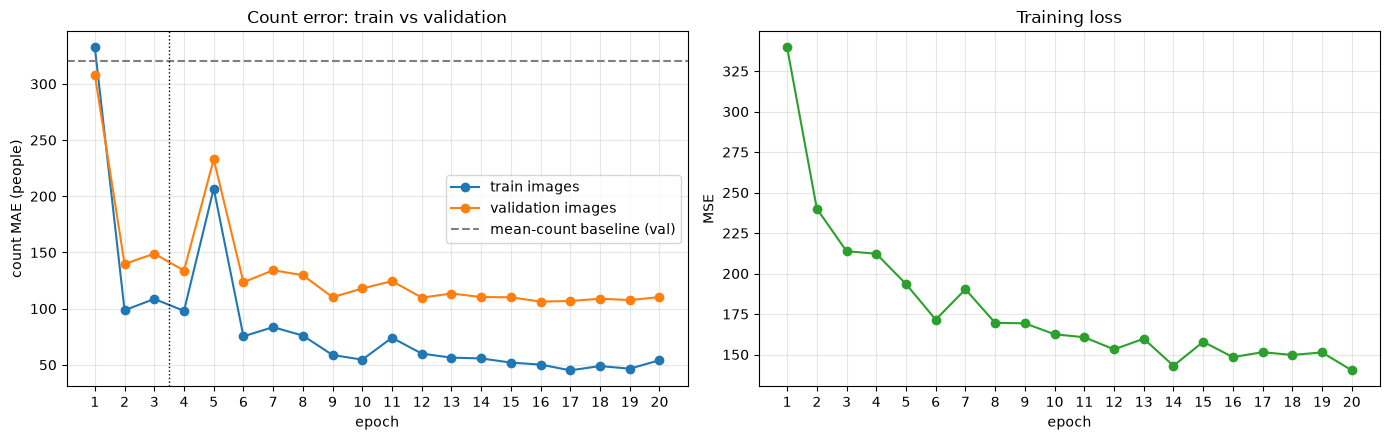

Epoch 1/20 (LR 3e-05, VGG-16 frozen)


  1/128 ━━━━━━━━━━━━━━━━━━━━ 9:10 4s/step - loss: 74.0431

  2/128 ━━━━━━━━━━━━━━━━━━━━ 3:07 1s/step - loss: 122.3207

  3/128 ━━━━━━━━━━━━━━━━━━━━ 3:11 2s/step - loss: 126.4042

  4/128 ━━━━━━━━━━━━━━━━━━━━ 3:07 2s/step - loss: 135.5402

  5/128 ━━━━━━━━━━━━━━━━━━━━ 3:02 1s/step - loss: 171.5736

... (2,591 outputs left out)

127/128 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - loss: 140.6633

128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - loss: 140.2282

128/128 ━━━━━━━━━━━━━━━━━━━━ 171s 1s/step - loss: 140.2282


  -> train MAE 54.1 | val MAE 110.3, RMSE 200.3 | 226s | no improvement (4)
  -> halving learning rate to 3.125e-07

Done in 360.0 min. Best val MAE 106.3 at epoch 16.


In [10]:
history = {"epoch": [], "loss": [], "train_mae": [], "val_mae": [], "val_rmse": [], "lr": []}
best_mae, best_epoch, since_best, since_lr_cut = np.inf, 0, 0, 0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
handle = display(fig, display_id=True)
plt.close(fig)

def redraw():
    for a in (ax1, ax2): a.clear()
    ax1.plot(history["epoch"], history["train_mae"], "o-", label="train images")
    ax1.plot(history["epoch"], history["val_mae"], "o-", label="validation images")
    ax1.axhline(base_val[0], ls="--", c="gray", label="mean-count baseline (val)")
    ax1.axvline(FREEZE_EPOCHS + 0.5, ls=":", c="k", lw=1)
    ax1.set(xlabel="epoch", ylabel="count MAE (people)", title="Count error: train vs validation")
    ax1.legend()
    ax2.plot(history["epoch"], history["loss"], "o-", c="C2")
    ax2.set(xlabel="epoch", ylabel="MSE", title="Training loss")
    for a in (ax1, ax2): a.set_xticks(history["epoch"]); a.grid(alpha=.3)
    fig.tight_layout(); handle.update(fig)

LOG_FILE = os.path.join(WEIGHTS_DIR, "csrnet_partA_v2_train_log.txt")
open(LOG_FILE, "w").close()
_print = print
def print(*args, **kwargs):   # also append every progress line to a log file
    _print(*args, **kwargs)
    with open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(time.strftime("%H:%M:%S ") + " ".join(str(a) for a in args) + "\n")

t_start = time.time()
for epoch in range(1, EPOCHS + 1):
    if epoch == FREEZE_EPOCHS + 1:
        front.trainable = True
        for layer in front.layers:
            layer.trainable = layer.name.startswith(FINETUNE_BLOCKS)
        model.compile(optimizer=tf.keras.optimizers.Adam(LR_FINETUNE), loss="mse")
        since_lr_cut = 0
        n_tr = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
        print(f"--- Unfroze VGG-16 {', '.join(FINETUNE_BLOCKS)} ({n_tr:,} trainable params), LR {LR_FINETUNE:g} ---")

    lr = float(model.optimizer.learning_rate.numpy())
    print(f"Epoch {epoch}/{EPOCHS} (LR {lr:g}, VGG-16 {'block4 trainable' if front.trainable else 'frozen'})")
    t0 = time.time()
    fit = model.fit(train_ds, epochs=1, steps_per_epoch=STEPS_PER_EPOCH, verbose=1)
    train_mae, _, _ = evaluate(train_check)
    val_mae, val_rmse, _ = evaluate(val)

    improved = val_mae < best_mae
    if improved:
        best_mae, best_epoch, since_best, since_lr_cut = val_mae, epoch, 0, 0
        model.save_weights(BEST_WEIGHTS)
    else:
        since_best += 1
        since_lr_cut += 1

    for k, v in zip(history, [epoch, fit.history["loss"][0], train_mae, val_mae, val_rmse, lr]):
        history[k].append(v)
    redraw()
    print(f"  -> train MAE {train_mae:.1f} | val MAE {val_mae:.1f}, RMSE {val_rmse:.1f} | "
          f"{time.time()-t0:.0f}s | {'saved new best' if improved else f'no improvement ({since_best})'}")

    if since_best >= EARLY_STOP_PATIENCE:
        print(f"Early stopping: no val improvement for {EARLY_STOP_PATIENCE} epochs.")
        break
    if since_lr_cut >= LR_PATIENCE:
        model.optimizer.learning_rate.assign(lr * 0.5)
        since_lr_cut = 0
        print(f"  -> halving learning rate to {lr*0.5:g}")

print(f"\nDone in {(time.time()-t_start)/60:.1f} min. Best val MAE {best_mae:.1f} at epoch {best_epoch}.")
with open(os.path.join(WEIGHTS_DIR, "csrnet_partA_v2_history.json"), "w") as f:
    json.dump(history, f, indent=1)
print = _print

## 9. Test set results

Load the best-epoch weights (by validation MAE) and count all 182 test images. The test set was
not used for any decision during training.

In [11]:
model.load_weights(BEST_WEIGHTS)
t0 = time.time()
test_mae, test_rmse, test_preds = evaluate(test)
test_true = np.array([it["count"] for it in test])
print(f"Counted {len(test)} test images in {time.time()-t0:.0f}s\n")

rows = [("Mean-count baseline", *base_test),
        ("CSRNet v1 (yesterday: best epoch 2 of 5)", 94.3, 130.7),
        (f"CSRNet v2 (best of {len(history['epoch'])} epochs, epoch {best_epoch})", test_mae, test_rmse),
        ("CSRNet, published paper (~400 epochs)", 68.2, 115.0)]
print(f"{'Method':<55}{'MAE':>8}{'RMSE':>9}")
for name, m, r in rows:
    print(f"{name:<55}{m:>8.1f}{r:>9.1f}")
print(f"\nImprovement over baseline: {100*(1-test_mae/base_test[0]):.0f}% lower MAE")

Counted 182 test images in 105s

Method                                                      MAE     RMSE
Mean-count baseline                                       301.8    368.6
CSRNet v1 (yesterday: best epoch 2 of 5)                   94.3    130.7
CSRNet v2 (best of 20 epochs, epoch 16)                    79.6    112.2
CSRNet, published paper (~400 epochs)                      68.2    115.0

Improvement over baseline: 74% lower MAE


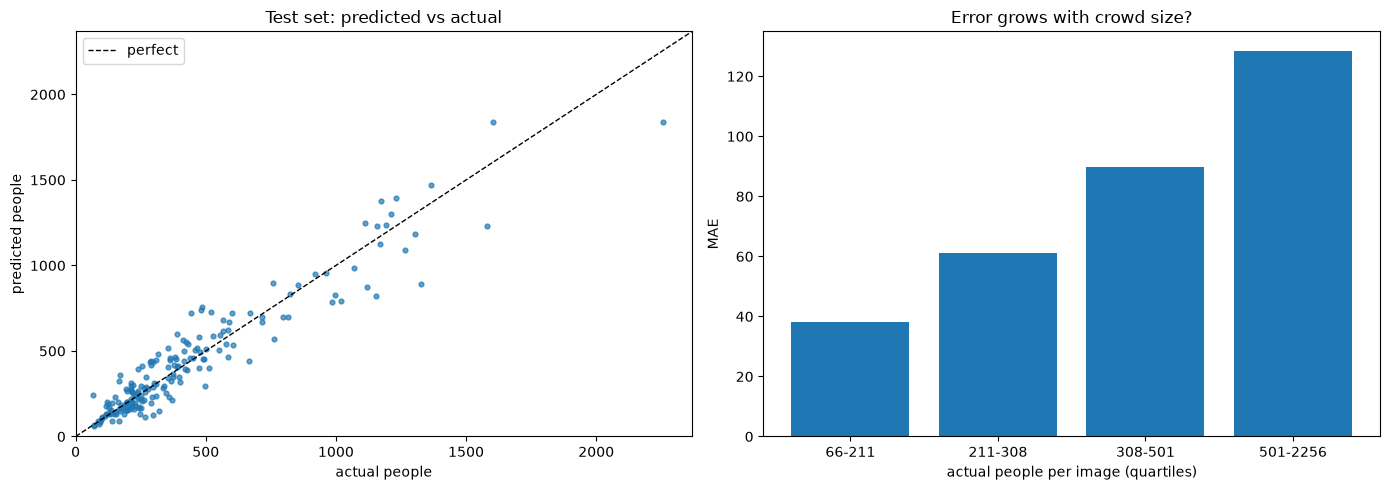

Average signed error: +3.0 people (negative = undercounts)


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
lim = max(test_true.max(), test_preds.max()) * 1.05
ax[0].scatter(test_true, test_preds, s=12, alpha=.7)
ax[0].plot([0, lim], [0, lim], "k--", lw=1, label="perfect")
ax[0].set(xlabel="actual people", ylabel="predicted people", title="Test set: predicted vs actual", xlim=(0, lim), ylim=(0, lim))
ax[0].legend()

bins = np.quantile(test_true, [0, .25, .5, .75, 1])
which = np.clip(np.digitize(test_true, bins[1:-1]), 0, 3)
labels = [f"{bins[i]:.0f}-{bins[i+1]:.0f}" for i in range(4)]
ax[1].bar(labels, [np.abs(test_preds - test_true)[which == i].mean() for i in range(4)])
ax[1].set(xlabel="actual people per image (quartiles)", ylabel="MAE", title="Error grows with crowd size?")
plt.tight_layout(); plt.show()

print(f"Average signed error: {np.mean(test_preds - test_true):+.1f} people (negative = undercounts)")

## 10. Sample predictions

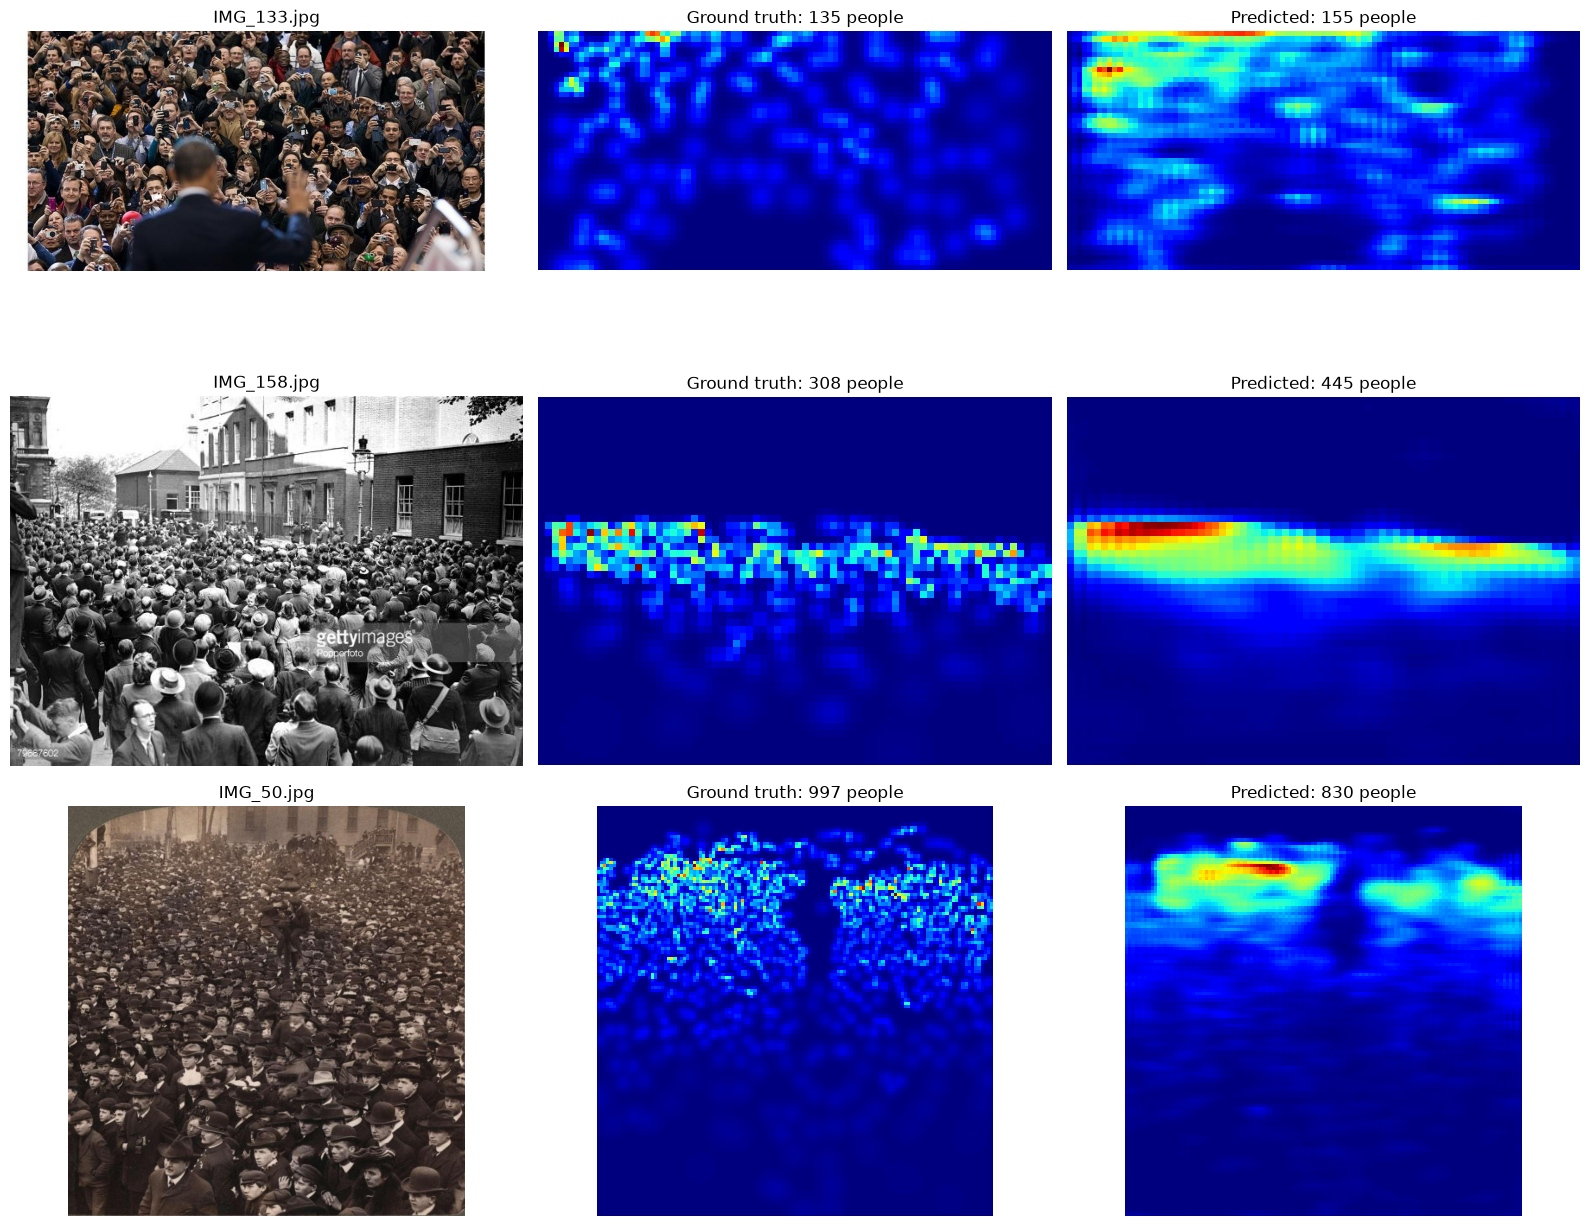

In [13]:
order = np.argsort(test_true)
picks = [order[len(order) // 10], order[len(order) // 2], order[-len(order) // 10]]   # sparse, medium, dense
fig, ax = plt.subplots(3, 3, figsize=(16, 13))
for row, i in enumerate(picks):
    it = test[i]
    pred, pmap = predict_count(it, return_map=True)
    h, w = it["image"].shape[:2]
    ax[row, 0].imshow(it["image"]); ax[row, 0].set_title(it["name"])
    ax[row, 1].imshow(it["density"][:h // 8, :w // 8], cmap="jet"); ax[row, 1].set_title(f"Ground truth: {it['count']:.0f} people")
    ax[row, 2].imshow(np.maximum(pmap[:h // 8, :w // 8], 0), cmap="jet"); ax[row, 2].set_title(f"Predicted: {pred:.0f} people")
    for a in ax[row]: a.axis("off")
plt.tight_layout(); plt.show()

## 11. v1 vs v2 on the same test images

Reloads yesterday's v1 weights and recounts all 182 test images, then compares both versions by crowd size.
Sparse photos were v1's weak spot.

v1 recount: MAE 94.3, RMSE 130.7 (104s)

Actual people (quartile)   images   v1 MAE   v2 MAE  v1 bias  v2 bias
66-211                         45     47.6     38.3    +16.9    +15.2
211-308                        46     71.5     61.1    +14.3     +8.6
308-501                        45    107.8     89.6    +49.0    +29.2
501-2256                       46    149.5    128.6    -27.4    -40.1
All                           182     94.3     79.6    +13.0     +3.0

bias = average (predicted - actual); positive means overcounting


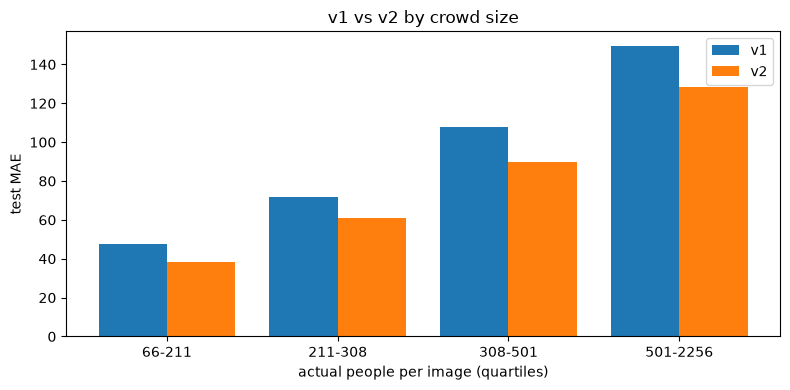

In [14]:
v2_preds = test_preds.copy()
model.load_weights(V1_WEIGHTS)
t0 = time.time()
v1_mae, v1_rmse, v1_preds = evaluate(test)
model.load_weights(BEST_WEIGHTS)   # back to v2
print(f"v1 recount: MAE {v1_mae:.1f}, RMSE {v1_rmse:.1f} ({time.time()-t0:.0f}s)\n")

print(f"{'Actual people (quartile)':<26}{'images':>7}{'v1 MAE':>9}{'v2 MAE':>9}{'v1 bias':>9}{'v2 bias':>9}")
for i in range(4):
    m = which == i
    print(f"{labels[i]:<26}{m.sum():>7}{np.abs(v1_preds-test_true)[m].mean():>9.1f}{np.abs(v2_preds-test_true)[m].mean():>9.1f}"
          f"{(v1_preds-test_true)[m].mean():>+9.1f}{(v2_preds-test_true)[m].mean():>+9.1f}")
print(f"{'All':<26}{len(test):>7}{v1_mae:>9.1f}{test_mae:>9.1f}"
      f"{(v1_preds-test_true).mean():>+9.1f}{(v2_preds-test_true).mean():>+9.1f}")
print("\nbias = average (predicted - actual); positive means overcounting")

x = np.arange(4)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - .2, [np.abs(v1_preds-test_true)[which == i].mean() for i in range(4)], .4, label="v1")
ax.bar(x + .2, [np.abs(v2_preds-test_true)[which == i].mean() for i in range(4)], .4, label="v2")
ax.set_xticks(x, labels); ax.set(xlabel="actual people per image (quartiles)", ylabel="test MAE", title="v1 vs v2 by crowd size")
ax.legend(); plt.tight_layout(); plt.show()